In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import roc_auc_score,precision_score, recall_score,f1_score

In [6]:
url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   object 
 1   industry                  4760 non-null   object 
 2   employment_status         4806 non-null   object 
 3   location                  4792 non-null   object 
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), object(4)
memory usage: 351.7+ KB


In [8]:
df.isna().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [9]:
numerical_cols = df.select_dtypes(include=["number"]).columns
categorical_cols = df.select_dtypes(include=["object"]).columns

In [10]:
df[numerical_cols] = df[numerical_cols].fillna(0.0)
df[categorical_cols] = df[categorical_cols].fillna("NA")

In [11]:
df.isna().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [12]:
df_full_train, df_test = train_test_split( df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train,test_size=0.25, random_state=1)

# Reset indexes
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# Separate target variable
y_train = df_train["converted"].values
y_val = df_val["converted"].values
y_test = df_test["converted"].values

# Remove target from features
del df_train["converted"]
del df_val["converted"]
del df_test["converted"]

print("Training:", df_train.shape)
print("Validation:", df_val.shape)
print("Testing:", df_test.shape)

Training: (3000, 8)
Validation: (1000, 8)
Testing: (1000, 8)


### Question 1

In [13]:
features = ["lead_score", "number_of_courses_viewed","interaction_count", "annual_income"]

# Calculate ROC AUC 
for feature in features:
    auc = roc_auc_score(y_train,df_train[feature])
    if auc < 0.5:
        auc = roc_auc_score(y_train,-df_train[feature] )
    print(f"{feature}: {auc:.4f}")

lead_score: 0.7882
number_of_courses_viewed: 0.7230
interaction_count: 0.7649
annual_income: 0.6082


In [14]:
auc_scores = {}
for feature in features:
    auc = roc_auc_score(y_train, df_train[feature])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[feature])
    auc_scores[feature] = auc
best_feature = max(auc_scores, key=auc_scores.get)
print("Feature with highest AUC:", best_feature)
print("Highest AUC:", auc_scores[best_feature])

Feature with highest AUC: lead_score
Highest AUC: 0.7882254810906102


### Question 2

In [16]:
train_dict = df_train.to_dict(orient="records")
val_dict = df_val.to_dict(orient="records")
dv = DictVectorizer(sparse=True)

X_train = dv.fit_transform(train_dict)
X_val = dv.transform(val_dict)

In [17]:
model = LogisticRegression( solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
print("Validation AUC:", round(auc, 3))

Validation AUC: 0.732


### Question 3

In [18]:
thresholds = np.arange(0.0, 1.01, 0.01)
precision_list = []
recall_list = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)
    precision = precision_score( y_val, y_pred_binary, zero_division=0)
    recall = recall_score( y_val,y_pred_binary, zero_division=0)
    precision_list.append(precision)
    recall_list.append(recall)

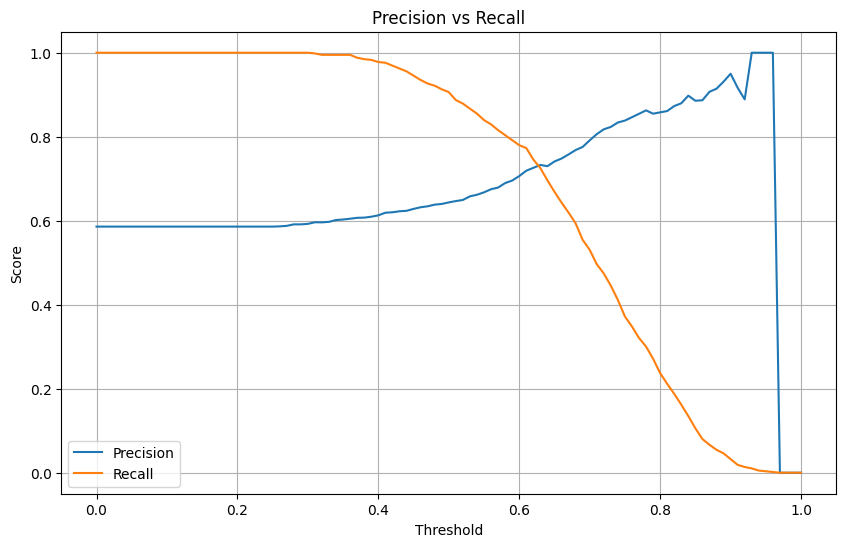

In [19]:
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision_list, label="Precision")
plt.plot( thresholds, recall_list, label="Recall")

plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Precision vs Recall")

plt.legend()
plt.grid(True)
plt.show()

In [20]:
precision_array = np.array(precision_list)
recall_array = np.array(recall_list)
difference = np.abs(precision_array - recall_array)
valid = (precision_array != 0) | (recall_array != 0)
valid_indices = np.where(valid)[0]

best_idx = valid_indices[
    np.argmin(difference[valid_indices])
]

best_threshold = thresholds[best_idx]

print("Best threshold:", best_threshold)
print("Precision:", precision_array[best_idx])
print("Recall:", recall_array[best_idx])
print("Difference:", difference[best_idx])

Best threshold: 0.63
Precision: 0.7327586206896551
Recall: 0.7252559726962458
Difference: 0.007502647993409384


### Question 4

In [21]:
f1_scores = []

for threshold in thresholds:
    y_pred_binary = (y_pred >= threshold).astype(int)
    precision = precision_score( y_val,y_pred_binary,zero_division=0 )
    recall = recall_score( y_val,y_pred_binary, zero_division=0)
    if precision + recall == 0:
        f1 = 0
    else:
        f1 = 2 * precision * recall / (precision + recall)

    f1_scores.append(f1)

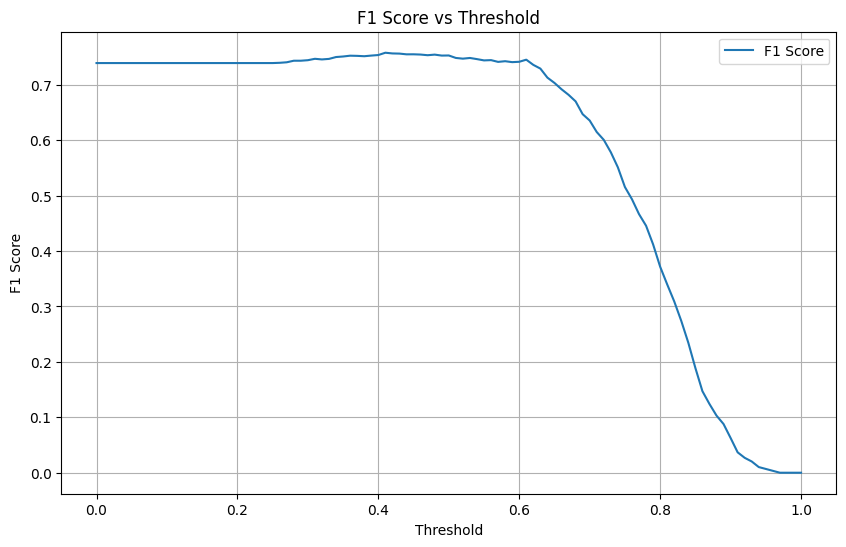

In [22]:
plt.figure(figsize=(10, 6))

plt.plot(thresholds, f1_scores,label="F1 Score")

plt.xlabel("Threshold")
plt.ylabel("F1 Score")
plt.title("F1 Score vs Threshold")

plt.legend()
plt.grid(True)
plt.show()

In [23]:
best_f1_idx = np.argmax(f1_scores)

best_f1_threshold = thresholds[best_f1_idx]
best_f1_score = f1_scores[best_f1_idx]

print("Best threshold:", best_f1_threshold)
print("Maximum F1 Score:", best_f1_score)

Best threshold: 0.41000000000000003
Maximum F1 Score: 0.7576158940397352


### Question 5

In [25]:
kfold = KFold( n_splits=5,shuffle=True,random_state=1)
y_full_train = df_full_train["converted"].values
df_full_train_features = df_full_train.drop(columns=["converted"])
scores = []

for train_idx, val_idx in kfold.split(df_full_train_features):
    df_fold_train = df_full_train_features.iloc[train_idx]
    df_fold_val = df_full_train_features.iloc[val_idx]
    y_fold_train = y_full_train[train_idx]
    y_fold_val = y_full_train[val_idx]

    train_dict = df_fold_train.to_dict(orient="records")
    val_dict = df_fold_val.to_dict(orient="records")


    dv = DictVectorizer(sparse=True)

    X_fold_train = dv.fit_transform(train_dict)
    X_fold_val = dv.transform(val_dict)


    model = LogisticRegression(solver="liblinear",C=1.0,max_iter=1000)
    # Train model
    model.fit(X_fold_train, y_fold_train)

    # Predict probabilities
    y_fold_pred = model.predict_proba(X_fold_val)[:, 1]

    # Calculate AUC
    auc = roc_auc_score(y_fold_val, y_fold_pred)

    scores.append(auc)

    print(f"AUC: {auc:.4f}")

AUC: 0.7306
AUC: 0.7296
AUC: 0.7363
AUC: 0.7412
AUC: 0.7209


In [26]:
print("\nCross-validation results")
print("Mean AUC:", round(np.mean(scores), 3))
print("Standard deviation:", round(np.std(scores), 3))


Cross-validation results
Mean AUC: 0.732
Standard deviation: 0.007


### Question 6

In [28]:
C_values = [0.000001, 0.001, 1]

C_values = [0.000001, 0.001, 1]

results = []

for C in C_values:

    scores = []

    kfold = KFold(n_splits=5,shuffle=True,random_state=1)
    for train_idx, val_idx in kfold.split(df_full_train_features):
        # Split data
        df_fold_train = df_full_train_features.iloc[train_idx]
        df_fold_val = df_full_train_features.iloc[val_idx]

        y_fold_train = y_full_train[train_idx]
        y_fold_val = y_full_train[val_idx]

        # Convert into dictionaries
        train_dict = df_fold_train.to_dict(orient="records")
        val_dict = df_fold_val.to_dict(orient="records")

        # One-hot encoding
        dv = DictVectorizer(sparse=True)

        X_fold_train = dv.fit_transform(train_dict)
        X_fold_val = dv.transform(val_dict)

        # Initialize model
        model = LogisticRegression(solver="liblinear",C=C,max_iter=1000)
        # Train
        model.fit(X_fold_train, y_fold_train)

        # Predict probabilities
        y_fold_pred = model.predict_proba(X_fold_val)[:, 1]

        # Calculate AUC
        auc = roc_auc_score(y_fold_val, y_fold_pred)

        scores.append(auc)

    # Calculate mean and standard deviation
    mean_auc = np.mean(scores)
    std_auc = np.std(scores)

    results.append({
        "C": C,
        "Mean AUC": mean_auc,
        "Std AUC": std_auc
    })

    print(
        f"C = {C}: "
        f"Mean AUC = {mean_auc:.3f}, "
        f"Std = {std_auc:.3f}"
    )

C = 1e-06: Mean AUC = 0.617, Std = 0.019
C = 0.001: Mean AUC = 0.749, Std = 0.010
C = 1: Mean AUC = 0.732, Std = 0.007


In [29]:
results_df = pd.DataFrame(results)

display(results_df)

results_df = results_df.sort_values(
    by=["Mean AUC", "Std AUC", "C"],
    ascending=[False, True, True])

best_C = results_df.iloc[0]["C"]

print("Best C:", best_C)

,C,Mean AUC,Std AUC
0,0.000001,0.616734,0.018670
1,0.001000,0.749172,0.009996
2,1.000000,0.731727,0.006853


Best C: 0.001
